### **Supervised Learning**

In [39]:
import warnings
warnings.filterwarnings('ignore')

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import entropy
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

### 🌳 **Decision Tree**

<img src="../../images/heart_attack.png" alt="classification" width=800>

[Decision Tree](https://scikit-learn.org/stable/modules/tree.html) - გამოიყენება კლასიფიკაციისა და რეგრესიისთვის. პროგნოზის გასაკეთებლად ის ყოფს მონაცემებს და იყენებს ხის სქტრუქტურას. 

- ფესვური კვანძი (Root Node) → მოიცავს მთელ მონაცემთა ბაზას.  
- შიდა კვანძები (Internal Nodes) → გადაწყვეტილების წერტილები, სადაც მონაცემები იყოფა.  
- ფოთლოვანი კვანძები (Leaf Nodes) → საბოლოო კლასიფიკაცია ან რიცხვითი მნიშვნელობა.

---
 
როგორ მუშაობს?
1. ირჩევა საუკეთესო ცვლადი მონაცემების გასაყოფად  
2. მონაცემები იყოფა ორ ან მეტ ქვეჯგუფად 
3. პროცესი მეორდება მანამ, სანამ შესრულდება გარკვეული პირობა (მაგ. ხის სიღრმე)  
4. შედეგი გამოითვლება ფოთლოვან კვანძებში

---

მონაცემთა გაყოფის კრიტერიუმი
- Gini ინდექსი → ზომავს სიწმინდეს (უფრო დაბალი Gini ნიშნავს უკეთეს დაყოფას).  
$Gini = 1 - \sum p_i^2$

- ენტროპია → ზომავს გაურკვევლობას.  
  $Entropy = -\sum p_i \log_2(p_i)$

- გადაწყვეტილების ხეები მონაცემებს ყოფენ ქვეჯგუფებად და იღებენ გადაწყვეტილებებს.  
- ისინი გამოიყენებიან კლასიფიკაციისა და რეგრესიისთვის.  
- შესაძლებელია Overfitting, რის თავიდან ასაცილებლად საჭიროა პარამეტრების (მაგ. `max_depth`) გამოყენება.  
- მარტივი ინტერპრეტაცია, მაგრამ ზოგჯერ სხვა ალგორითმებთან შედარებით უფრო ზუსტია (მაგ. Random Forest).

### Is today a good day to play tennis?

In [41]:
data = {
    "Day": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
    "Outlook": ["sunny", "sunny", "overcast", "rainy", "rainy", "rainy", "overcast", "sunny", "sunny", "rainy", "sunny", "overcast", "overcast", "rainy"],
    "Temperature": ["hot", "hot", "hot", "mild", "cold", "cold", "cold", "mild", "cold", "mild", "mild", "mild", "hot", "mild"],
    "Humidity": ["high", "high", "high", "high", "normal", "normal", "normal", "high", "normal", "normal", "normal", "high", "normal", "high"],
    "Wind": ["strong", "weak", "strong", "strong", "strong", "weak", "weak", "strong", "strong", "strong", "weak", "weak", "strong", "weak"],
    "Playing_Tennis": ["no", "no", "yes", "yes", "yes", "no", "yes", "no", "yes", "yes", "yes", "yes", "yes", "no"]
}

df = pd.DataFrame(data)
df = df.set_index("Day")
df 

,Outlook,Temperature,Humidity,Wind,Playing_Tennis
Day,,,,,
1,sunny,hot,high,strong,no
2,sunny,hot,high,weak,no
3,overcast,hot,high,strong,yes
4,rainy,mild,high,strong,yes
5,rainy,cold,normal,strong,yes
6,rainy,cold,normal,weak,no
7,overcast,cold,normal,weak,yes
8,sunny,mild,high,strong,no
9,sunny,cold,normal,strong,yes


### Decision Tree Example

<img src="../../images/tennis_example.png" alt="classification" width=800>

გადაწყვეტილების ხე მუშაობს if-then პრინციპით:

**Algorithm: DecideTennis**

**if** Outlook = sunny **then**  
&nbsp;&nbsp;&nbsp;&nbsp;**if** Humidity = high **then return** no  
&nbsp;&nbsp;&nbsp;&nbsp;**if** Humidity = low **then return** yes  

**if** Outlook = overcast **then**  
&nbsp;&nbsp;&nbsp;&nbsp;return yes  

**if** Outlook = rainy **then**  
&nbsp;&nbsp;&nbsp;&nbsp;**if** Wind = strong **then return** no  
&nbsp;&nbsp;&nbsp;&nbsp;**if** Wind = weak **then return** yes


14 data records (yes: 9, no: 5), რომელი ატრიბუტი უნდა ავარჩიოთ მონაცემების გასაყოფად? (first split)?

<img src="../../images/dt_split.png" alt="classification" width=800>

#### Gini-Impurity (Gini Index)
Gini-ინდექსი არის მახასიათებელი, რომელიც ზომავს კვანძის სისუფთავეს გადაწყვეტილების ხეში.

ფორმულა:

$Gini = 1 - \sum_{i=1}^{C} p_i^2$

სადაც: 
- $C$ → კლასების რაოდენობა  
- $p_i$ → მონაცემთა წილი კლასში $i$  

- $Gini = 0$ → იდეალური სისუფთავე (ყველა მონაცემი ერთ კლასშია).  
- $Gini = 0.5$ → მაქსიმალური არაწმინდე (ორი კლასი თანაბრადაა გადანაწილებული).

დავითვალოთ Gini ინდექსი. როგორც ზემოთ ვნახეთ, გადაწყვეტილება შეგვიძლია ტემპერატურის მაჩვენებლის მიუხედავად მივიღოთ, ამიტომაც დავფოკუსირდეთ Himidity, Wind & Outlook-ის მნიშვნელობებზე.

---

### $Gini_{\text{parent}}$

14 ჩანაწერი → (yes = 9, no = 5)

$Gini_{\text{parent}} = 1 - (\left(\frac{9}{14}\right)^2 + \left(\frac{5}{14}\right)^2) = 1 - \frac{81+25}{196} = \frac{90}{196} \approx 0.459$

---

### Humidity

- high: 7 ჩანაწერი → (yes = 3, no = 4)


  $Gini_{\text{high}} = 1 - \left(\frac{3}{7}\right)^2 - \left(\frac{4}{7}\right)^2 
  \approx 1 - (0.1849 + 0.3265) = 1 - 0.5114 \approx 0.49$

- normal: 7 ჩანაწერი → (yes = 6, no = 1)

  
  $Gini_{\text{normal}} = 1 - \left(\frac{6}{7}\right)^2 - \left(\frac{1}{7}\right)^2 
  \approx 1 - (0.7347 + 0.0204) = 1 - 0.7551 \approx 0.245$

---
### Wind
- strong: 8 ჩანაწერი → (yes = 6, no = 2)

  
  $Gini_{\text{strong}} = 1 - \left(\frac{6}{8}\right)^2 - \left(\frac{2}{8}\right)^2 
  = 1 - (0.5625 + 0.0625) = 1 - 0.625 = 0.375$

- weak: 6 ჩანაწერი → (yes = 3, no = 3)

  
  $Gini_{\text{weak}} = 1 - \left(\frac{3}{6}\right)^2 - \left(\frac{3}{6}\right)^2 
  = 1 - (0.25 + 0.25) = 1 - 0.5 = 0.5$

---

### Outlook

- sunny: 5 ჩანაწერი → (yes = 2, no = 3)  
  
  $Gini_{\text{sunny}} = 1 - \left(\frac{2}{5}\right)^2 - \left(\frac{3}{5}\right)^2 
  = 1 - (0.16 + 0.36) = 1 - 0.52 = 0.48$

- overcast: 4 ჩანაწერი → (yes = 4, no = 0)

  
  $Gini_{\text{overcast}} = 1 - 1^2 - 0^2 = 0$

- rainy: 5 ჩანაწერი → (yes = 3, no = 2)


  $Gini_{\text{rainy}} = 1 - \left(\frac{3}{5}\right)^2 - \left(\frac{2}{5}\right)^2 
  = 1 - (0.36 + 0.16) = 1 - 0.52 = 0.48$

---

<img src="../../images/gini.png" alt="classification" width=800>

### Gini-Gain (reduction in impurity after a split):

მშობლის ჯინის ინდექსიდან ვაკლებთ შვილების ჯინის წონიან საშუალოს.

  $\text{Gini Gain} = Gini_{\text{parent}} - \sum_{i=1}^{k} \frac{N_i}{N_{\text{parent}}} \times Gini(\text{child}_i)$

დავითვალოთ თითოეული ატრიბუტისთვის: 
### Humidity

$Gini_{\text{Humidity}} = \frac{7}{14} \times 0.49 + \frac{7}{14} \times 0.245 
= 0.5 \times (0.49 + 0.245) 
= 0.5 \times 0.7335 \approx 0.367$

$Gini\text{-gain(Humidity)} = Gini_{\text{parent}} - Gini_{\text{Humidity}} \approx 0.46 - 0.367 = 0.093$

---
### Wind

$Gini_{\text{Wind}} = \frac{8}{14} \times 0.375 + \frac{6}{14} \times 0.5 
\approx 0.214 + 0.214 \approx 0.429$ 

$Gini\text{-gain(Wind)} = Gini_{\text{parent}} - Gini_{\text{Wind}} 
\approx 0.46 - 0.429 = 0.031$

---

#### Outlook

$Gini_{\text{Outlook}} = \frac{5}{14}\times 0.48 + \frac{4}{14}\times 0 + \frac{5}{14}\times 0.48 
= 0.48 \times \frac{10}{14} \approx 0.48 \times 0.7143 \approx 0.343$

$Gini\text{-gain(Outlook)} = Gini_{\text{parent}} - Gini_{\text{Outlook}} 
\approx  0.46 - 0.343 = 0.117$

---

### შედარება და საბოლოო გადაწყვეტილება

| ატრიბუტი       | Gini-gain  |
|-----------------|--------------|
| **Wind**       | ~0.03        |
| **Humidity**   | ~0.09        |
| **Outlook**    | ~0.12        |

Outlook ატრიბუტი იძლევა უმაღლეს Gini-Gain-ს (დაახლოებით 0.12) და ამიტომ ის ითვლება საუკეთესო პირველ გამყოფად.  

ახლა ენთროპიის შემთხვევაში დავითვალოთ:

$Entropy = -\sum p_i \log_2(p_i)$

ქვემოთ მოცემულია გამოთვლა ენთროპიის მიხედვით Himidity, Wind და Outlook მახასიათებლებისთვის. 

---

###  $Entropy_{\text{parent}}$

14 ჩანაწერი → (yes = 9, no = 5)

$Entropy_{\text{parent}} = -\left(\frac{9}{14}\log_2\frac{9}{14} + \frac{5}{14}\log_2\frac{5}{14}\right)\approx -\left(0.643\log_2 0.643 + 0.357\log_2 0.357\right) \approx 0.94$

---

### Himidity

- high 7 ჩანაწერი → (yes = 3, no = 4)

$Entropy_{\text{high}} = -\left(0.429\log_2 0.429 + 0.571\log_2 0.571\right)$
$\approx -\left(0.429 \times (-1.222) + 0.571 \times (-0.807)\right) \approx 0.985$

- normal 7 ჩანაწერი → (yes = 6, no = 1)

$Entropy_{\text{normal}} = -\left(0.857\log_2 0.857 + 0.143\log_2 0.143\right)$
$\approx -\left(0.857 \times (-0.222) + 0.143 \times (-2.807)\right) \approx 0.592$

---

### Wind

- strong 8 ჩანაწერი → (yes = 6, no = 2)

$Entropy_{\text{strong}} = -\left(0.75\log_2 0.75 + 0.25\log_2 0.25\right)$
$= -\left(0.75\times (-0.415) + 0.25\times (-2)\right) \approx 0.811$

- weak 6 ჩანაწერი → (yes = 3, no = 3)

$Entropy_{\text{weak}} = -\left(0.5\log_2 0.5 + 0.5\log_2 0.5\right) = 1$


---

### Outlook

- sunny 5 ჩანაწერი → (yes = 2, no = 3)

$Entropy_{\text{sunny}} = -\left(0.4\log_2 0.4 + 0.6\log_2 0.6\right)$
$\approx -\left(0.4\times (-1.322) + 0.6\times (-0.737)\right) \approx 0.971$

- overcast 4 ჩანაწერი → (yes = 4, no = 0)

$Entropy_{\text{overcast}} = 0 \quad (\text{რადგან ცალსახა “yes”})$

- rainy 5 ჩანაწერი → (yes = 3, no = 2)

$Entropy_{\text{rainy}} = -\left(0.6\log_2 0.6 + 0.4\log_2 0.4\right) \approx 0.971$

<img src="../../images/ig.png" alt="classification" width=800>

#### Information Gain (ინფორმაციის მოგება)
Information Gain (IG) არის მეტრიკა, რომელიც ზომავს, რამდენად ამცირებს ენთროპიას (გაურკვევლობას) კონკრეტული გაყოფა.  

ფორმულა:

$IG = Entropy_{parent} - \sum \frac{N_{child}}{N_{parent}} \times Entropy_{child}$

სადაც:  
- $Entropy_{parent}$ → საწყისი (ფესვური) კვანძის ენთროპია  
- $Entropy_{child}$ → შვილობილ კვანძებში დარჩენილი ენთროპია  
- $N_{child}$ → შვილობილი კვანძის ნიმუშების რაოდენობა  
- $N_{parent}$ → საწყისი (ფესვური) კვანძის ნიმუშების რაოდენობა  

- უფრო მაღალი Information Gain → უკეთესი გაყოფა, რადგან ის უკეთ ამცირებს არეულობას.

---


### Himidity

$Entropy_{\text{Humidity}} = \frac{7}{14}\times 0.985 + \frac{7}{14}\times 0.592 = 0.5\times (0.985+0.592) \approx 0.79$

$IG_{\text{Humidity}} = Entropy_{\text{parent}} - Entropy_{\text{Humidity}} \approx 0.94 - 0.79 = 0.15$

---

### Wind

$Entropy_{\text{Wind}} = \frac{8}{14}\times 0.811 + \frac{6}{14}\times 1.0 \approx 0.571\times 0.811 + 0.429\times 1.0 \approx 0.463 + 0.429 \approx 0.892$

$IG_{\text{Wind}} = Entropy_{\text{parent}} - Entropy_{\text{Wind}} \approx 0.94 - 0.892 = 0.048 \approx 0.05$

---

### Outlook

$Entropy_{\text{Outlook}} = \frac{5}{14}\times 0.971 + \frac{4}{14}\times 0 + \frac{5}{14}\times 0.971 = \frac{10}{14}\times 0.971 \approx 0.694$

$IG_{\text{Outlook}} = Entropy_{\text{parent}} - Entropy_{\text{Outlook}} \approx 0.94 - 0.694 = 0.246$

---

### შეჯამება

| მახასიათებელი  | \(IG\) (Information Gain) |
|------------------|---------------------------|
| **Humidity**     | ~0.15                     |
| **Wind**         | ~0.05                     |
| **Outlook**      | ~0.25                    |

Outlook ატრიბუტი აქვს უმაღლესი Information Gain და სწორედ იგივე ტენდენცია მიუთითებს, რომ ეს საუკეთესო პირველი გაყოფაა.

* ინფორმაციის მოგება (Information Gain) — გვიჩვენებს, რამდენად კარგად ყოფს ატრიბუტი მონაცემებს კლასებად. ითვლება ენტროპიის (მოწესრიგებლობის საზომი) შემცირებით.

* ენტროპია (Entropy) — რაც მეტია ენტროპია, მით მეტად შერეულია კლასები.

* ჯინის ინდექსი (Gini Index) — ასევე ზომავს შერეულობას. მნიშვნელობა მერყეობს 0-დან 0.5-მდე (binary კლასებისთვის). 0 ნიშნავს სუფთა (ერთი კლასის) გაყოფას.

* გინის მოგება (Gini Gain) — გვიჩვენებს, რამდენად შემცირდა შერეულობა გაყოფის შედეგად


| კრიტერიუმი        | ენტროპია (Entropy)                     | ჯინის ინდექსი (Gini Index)           |
|-------------------|-----------------------------------------|---------------------------------------|
| ეფუძნება          | ინფორმაციულ თეორიას                     | ალბათობის თეორიას                     |
| გამოთვლის სიჩქარე | შედარებით ნელია (ლოგარითმული ფუნქცია) | შედარებით სწრაფია (ლოგარითმის გარეშე) |

ენტროპია და ჯინი ხშირად ერთნაირ შედეგს იძლევიან, მაგრამ ჯინის ინდექსი უფრო სწრაფია გამოსათვლელად და ხშირად გამოიყენება.

### Iris flower data set

In [42]:
# ჩატვირთეთ Iris dataset seaborn-ის მეშვეობით
df_iris = sns.load_dataset("iris")
df_iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [43]:
# მხოლოდ 2 კლასი განვიხილოთ (versicolor & verginica)
df_iris_2 = df_iris[df_iris["species"] != "setosa"]

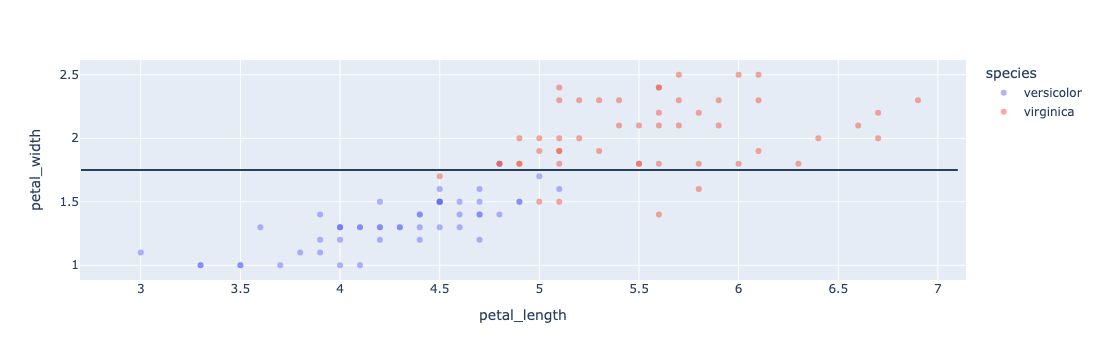

In [44]:
fig = px.scatter(df_iris_2, x="petal_length", y="petal_width", color="species", opacity=0.5)
fig.add_shape(x0=2.7, x1=7.1, y0=1.75, y1=1.75)
fig.update_layout(xaxis_title="petal_length", yaxis_title="petal_width")
fig.show()

In [45]:
# დავყოთ მონაცემები: features (X) და labels (y)
X = df_iris_2.drop(columns="species")
y = df_iris_2["species"]

In [46]:
# გავწვრთნათ Decision Tree მოდელი
model = DecisionTreeClassifier(max_depth=1)
model.fit(X, y)

,criterion,'gini'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


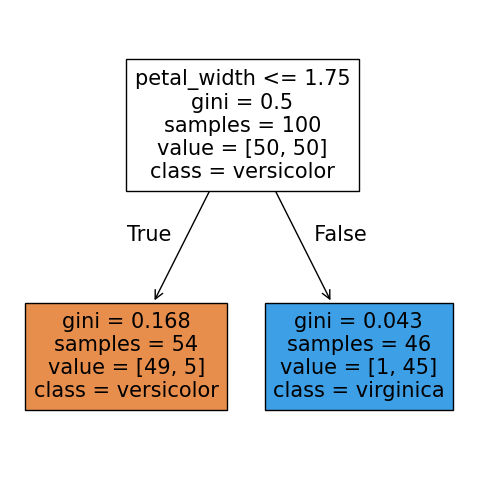

In [47]:
plt.figure(figsize=(6, 6))
plot_tree(model, feature_names=model.feature_names_in_, class_names=model.classes_, filled=True)
plt.show()

#### Gini-Impurity

$Gini = 1 - \sum_{i=1}^{C} p_i^2$

- კლასები: Versicolor, Virginica  
- ნიმუშების განაწილება: `[50, 50]`  
- სულ: `100`  
- კლასების ალბათობები:  
  - Versicolor:  $\frac{50}{100} $  
  - Virginica:  $\frac{50}{100} $  

$Gini(50, 50) = 1 - ((\frac{50}{100})^2+(\frac{50}{100})^2) = 1−(0.25+0.25)=1−0.5=0.5$

$Gini(49, 5) = 1 - ((\frac{49}{54})^2+(\frac{5}{54})^2) = 1-(\frac{2401}{2916}+ \frac{25}{2916} )= 1-\frac{2426}{2916}= \frac{2916 - 2426}{2916} = \frac{490}{2916}\approx0.168$

$Gini(1, 45) = 1 - ((\frac{1}{46})^2+(\frac{45}{46})^2) = 1-( \frac{1}{2116} + \frac{2025}{2116})= 1 - \frac{2026}{2116} = \frac{2116 - 2026}{2116} = \frac{90}{2116} \approx 0.043$

$Gini_{left} * weight_{left} + Gini_{right} * weight_{right} = 0.168 * \frac{54}{100} + 0.043 * \frac{46}{100} \approx 0.110$

როგორ ვიპოვოთ წირი, რომელიც მონაცემებს საუკეთესოდ ყოფს?

 - მოვძებნოთ მახასიათებელი $(a)$ და მნიშვნელობა $(t)$ , რომელზე დაფუძნებითაც გვინდა დაყოფა
   
    -> როგორ ავარჩიოთ მახასიათებელი და მნიშვნელობა? - მოვსინჯავთ ყველა მახასიათებელს და მათ მნიშვნელობებს
 - დავყოთ $X$ შესაბამისად $X_{a≤t}$ და $X_{a>t}$ ნაწილებად

In [48]:
values = sorted({float(x) for x in df_iris_2["petal_width"].values})
print(values)

[1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5]


| petal_width ≤ t | Versicolor (მარცხნივ) | Virginica (მარცხნივ) | Gini (მარცხნივ) | Versicolor (მარჯვნივ) | Virginica (მარჯვნივ) | Gini (მარჯვნივ) | წონიანი Gini |
|-----------------------------|----------------------|---------------------|--------------|-----------------------|----------------------|---------------|-----------------|
| petal_width ≤ 1.0           | 7                    | 0                   | 0.000        | 43                    | 50                   | 0.497         | 0.463           |
| petal_width ≤ 1.1           | 10                   | 0                   | 0.000        | 40                    | 50                   | 0.494         | 0.444           |
| petal_width ≤ 1.2           | 15                   | 0                   | 0.000        | 35                    | 50                   | 0.484         | 0.412           |
| petal_width ≤ 1.3           | 28                   | 0                   | 0.000        | 22                    | 50                   | 0.424         | 0.306           |
| petal_width ≤ 1.4           | 35                   | 1                   | 0.054        | 15                    | 49                   | 0.359         | 0.249           |
| petal_width ≤ 1.5           | 45                   | 3                   | 0.117        | 5                     | 47                   | 0.174         | 0.147           |
| petal_width ≤ 1.6           | 48                   | 4                   | 0.142        | 2                     | 46                   | 0.080         | 0.112           |
| petal_width ≤ 1.7           | 49                   | 5                   | 0.168        | 1                     | 45                   | 0.043         | 0.110           |
| petal_width ≤ 1.8           | 50                   | 16                  | 0.367        | 0                     | 34                   | 0.000         | 0.242           |
| petal_width ≤ 1.9           | 50                   | 21                  | 0.417        | 0                     | 29                   | 0.000         | 0.296           |
| petal_width ≤ 2.0           | 50                   | 27                  | 0.455        | 0                     | 23                   | 0.000         | 0.351           |
| petal_width ≤ 2.1           | 50                   | 33                  | 0.479        | 0                     | 17                   | 0.000         | 0.398           |
| petal_width ≤ 2.2           | 50                   | 36                  | 0.487        | 0                     | 14                   | 0.000         | 0.419           |
| petal_width ≤ 2.3           | 50                   | 44                  | 0.498        | 0                     | 6                    | 0.000         | 0.468           |
| petal_width ≤ 2.4           | 50                   | 47                  | 0.500        | 0                     | 3                    | 0.000         | 0.485           |
| petal_width ≤ 2.5           | 50                   | 50                  | 0.500        | 0                     | 0                    | 0.000         | 0.500           |


**petal_width ≤ 1.7**  -  აქვს მინიმალური წონიანი Gini.

- **petal_width ≤ 1.65:**  
  ეს ჯგუფი არის საშუალო მნიშვნელობა 1.6-ისა და 1.7-ის შორის.

- **petal_width ≤ 1.75:**  
  ეს ჯგუფი არის საშუალო მნიშვნელობა 1.7-ისა და 1.8-ის შორის.


|petal_width ≤ t| Versicolor (მარცხნივ) | Virginica (მარცხნივ) | Gini (მარცხნივ) | Versicolor (მარჯვნივ) | Virginica (მარჯვნივ) | Gini (მარჯვნივ) | წონიანი Gini |
|-----------------------------|------------------------|-----------------------|-----------------|-----------------------|----------------------|----------------|---------------|
| petal_width ≤ 1.65          | 48                     | 4                     | 0.142           | 2                     | 46                   | 0.080          | 0.112         |
| petal_width ≤ 1.75          | 49                     | 5                     | 0.168           | 1                     | 45                   | 0.043          | 0.110         |
    

რადგან 0.110 ნაკლებია 0.112-ზე, მოდელი აირჩევს პირობას **petal_width ≤ 1.75**, რადგან ეს უფრო უკეთესი გაყოფას იძლევა.

#### Entropy, Information Gain 

$Entropy = -\sum p_i \log_2(p_i)$

$IG = Entropy_{parent} - \sum \frac{N_{child}}{N_{parent}} \times Entropy_{child}$

#### 1. $Entropy_{parent}$
ორ კლასის შემთხვევაში, თუ Versicolor და Virginica განაწილებულია 50:50:

- $p_{Versicolor} = \frac{50}{100} = 0.5$
- $p_{Virginica} = \frac{50}{100} = 0.5$ 

მაშინ:

$Entropy_{parent} = -\left( 0.5 \log_2(0.5) + 0.5 \log_2(0.5) \right) = -\left( -0.5 - 0.5 \right) = 1.0$

---

#### 2. გაყოფა `petal_width ≤ 1.75`  
**მარცხენა კვანძი (`True` - petal_width ≤ 1.75):**

Versicolor = 49  
Virginica = 5  
სულ ნიმუშები = 54  

- $p_{Versicolor,left} = \frac{49}{54} \approx 0.9074,\quad$
- $ p_{Virginica,left} = \frac{5}{54} \approx 0.0926$
- $Entropy_{left} = -\left( 0.9074 \log_2(0.9074) + 0.0926 \log_2(0.0926) \right) \approx 0.446$

**მარჯვენა კვანძი (`False` - petal_width > 1.75):**

Versicolor = 1  
Virginica = 45  
სულ ნიმუშები = 46  

- $p_{Versicolor,right} = \frac{1}{46} \approx 0.0217,\quad$
- $ p_{Virginica,right} = \frac{45}{46} \approx 0.9783$
- $Entropy_{right} = -\left( 0.0217 \log_2(0.0217) + 0.9783 \log_2(0.9783) \right) \approx 0.151$

---

#### 3. წონიანი ენტროპია  
- $Weighted\ Entropy = \frac{54}{100} \times Entropy_{left} + \frac{46}{100} \times Entropy_{right}$
- $Weighted\ Entropy \approx 0.54 \times 0.446 + 0.46 \times 0.151 \approx 0.241 + 0.0695 \approx 0.3105$

---

#### 4. Information Gain-ის გამოთვლა  
$IG = Entropy_{parent} - Weighted\ Entropy = 1.0 - 0.3105 \approx 0.6895$

---
  
გაყოფა `petal_width ≤ 1.75` გვაძლევს $Information Gain=0.6895$, რაც მიუთითებს, რომ ეს გაყოფა მნიშვნელოვანად შემცირებს გაურკვევლობას (ენტროპიას).

### DecisionTree 3 კლასისთვის

In [49]:
# დავყოთ მონაცემები: features (X) და labels (y)
X = df_iris.drop(columns="species")
y = df_iris["species"]

# Train-test split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [50]:
# გავწვრთნათ Decision Tree მოდელი gini კრიტერიუმით და max_depth=3
model = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42) # criterion="entropy"
model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [51]:
# პროგნოზი
y_pred = model.predict(X_test)

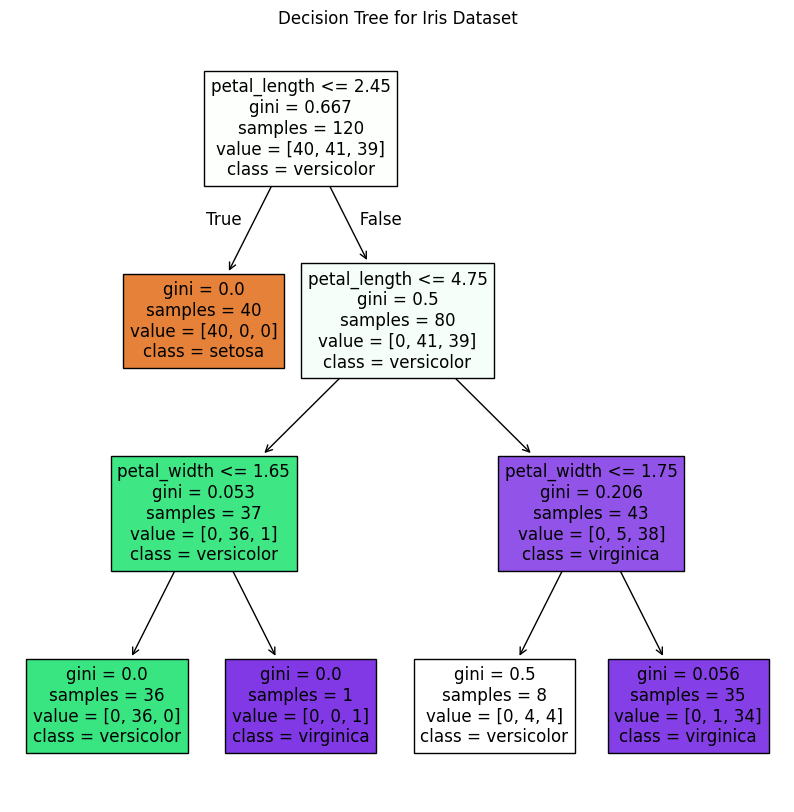

In [52]:
plt.figure(figsize=(10, 10))
plot_tree(model, feature_names=model.feature_names_in_, class_names=model.classes_, filled=True)
plt.title("Decision Tree for Iris Dataset")
plt.show()

Iris მონაცემებისათვის petal_length < 2.45 პირობა განსაკუთრებით დიდ ინფორმაციულ მოგებას გვაძლევს
ან Gini უსუფთაობას მნიშვნელოვნად ამცირებს. Iris setosa სახის ყვავილისთვის ეს მახასიათებელი 
ბევრად მცირეა ვიდრე დანარჩენი ორი სახეობისთვის (versicolor და virginica). 
ამ პირობით Iris setosa ძალიან ეფექტურად გამოიყოფა დანარჩენი ორი სახეობისგან. 
ამიტომ, ეს პირობა პირველი გამოჩნდება ხეში.

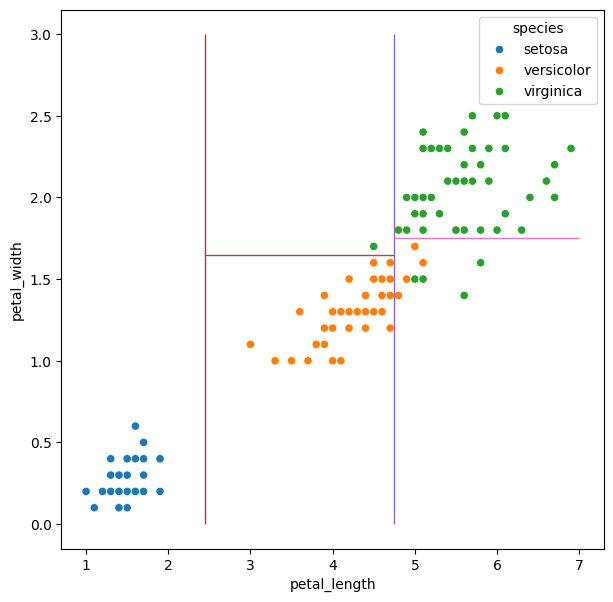

In [53]:
# ხეზე დაყრდნობით მონაცემების დაყოფა
fig, ax = plt.subplots(figsize=(7, 7))
sns.scatterplot(data=df_iris, x="petal_length", y="petal_width", hue="species", legend="full", ax=ax)
ax.vlines(2.45, ymin=0, ymax=3, color="C3", linewidth=1) # Root Node
ax.vlines(4.75, ymin=0, ymax=3, color="C4", linewidth=1) # Internal Node 1
ax.hlines(1.65, xmin=2.45, xmax=4.75, color="C5", linewidth=1) # Internal Node 2
ax.hlines(1.75, xmin=4.75, xmax=7, color="C6", linewidth=1) # Internal Node 3
ax.set_xlabel("petal_length")
ax.set_ylabel("petal_width");

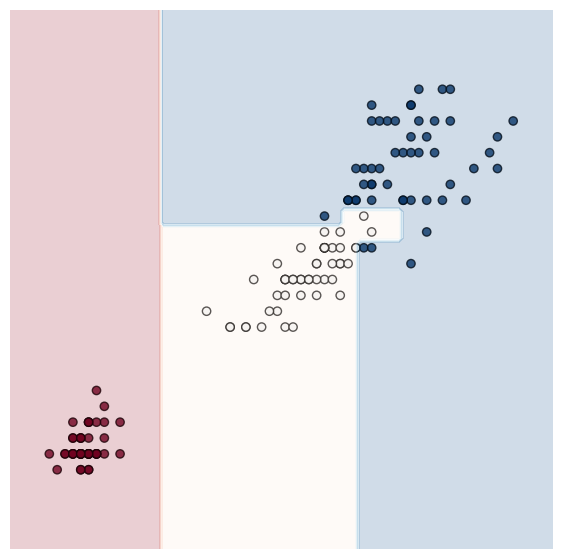

In [54]:
# Decision boundary: როგორ გამოყოფს მოდელი მონაცემებს ერთმანეთისგან
cm = plt.cm.RdBu
clf = DecisionTreeClassifier(random_state=42)  # max_depth პარამეტრის გარეშე
clf.fit(X_train[["petal_length", "petal_width"]], y_train)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X["petal_length"], X["petal_width"], c=y.astype("category").cat.codes, cmap=cm, edgecolor="k", alpha=0.8)
DecisionBoundaryDisplay.from_estimator(clf, X[["petal_length", "petal_width"]], response_method="predict", cmap=cm, alpha=0.2, ax=ax, eps=0.5)
plt.axis("off")
plt.show()

### Gini-Impurity

$Gini = 1 - \sum_{i=1}^{C} p_i^2$

----

Root Node ანალიზი:
- კლასები: Setosa, Versicolor, Virginica  
- ნიმუშების განაწილება: `[40, 41, 39]`  
- სულ: `40 + 41 + 39 = 120`  
- კლასების ალბათობები:  
  - Setosa:  $\frac{40}{120} = 0.333$  
  - Versicolor:  $\frac{41}{120} = 0.341$  
  - Virginica:  $\frac{39}{120} = 0.325$  

Gini-ის გამოთვლა ამ კვანძისთვის:

$Gini = 1 - (0.333^2 + 0.341^2 + 0.325^2) = 1 - (0.111 + 0.116 + 0.106) = 1 - 0.333 = 0.667$

### Entropy / Information Gain (ინფორმაციის მოგება)
$IG = Entropy_{parent} - \sum \frac{N_{child}}{N_{parent}} \times Entropy_{child}$

---

Information Gain-ის გამოთვლა Root Node-თვის:
- Setosa = 40
- Versicolor = 41
- Virginica = 39
- სულ ნიმუშები = 120

$Entropy = -\sum p_i \log_2(p_i)$, სადაც $p_i$ არის კლასების ალბათობები.

$Entropy_{parent} = -\left( \frac{40}{120} \log_2 \frac{40}{120} + \frac{41}{120} \log_2 \frac{41}{120} + \frac{39}{120} \log_2 \frac{39}{120} \right)$

$Entropy_{parent} = -\left( 0.333 \log_2 0.333 + 0.341 \log_2 0.341 + 0.325 \log_2 0.325 \right)$

$Entropy_{parent} = - ( -0.528 - 0.530 - 0.523 ) = 1.58$

---

გაყოფა `petal_length <= 2.45`-ზე
შედეგად ვიღებთ 2 კვანძს:
1. მარცხენა კვანძი (`True`)  
   - Setosa = 40 (100%)  
   - Versicolor, Virginica = 0  
   - სულ ნიმუშები = 40  
   - Entropy = 0 (რადგან ყველა ერთი კლასია)
   
2. მარჯვენა კვანძი (`False`)  
   - Versicolor = 41  
   - Virginica = 39  
   - სულ ნიმუშები = 80  
   - Entropy = ?  

$Entropy_{right} = -\left( \frac{41}{80} \log_2 \frac{41}{80} + \frac{39}{80} \log_2 \frac{39}{80} \right)$

$Entropy_{right} = -\left( 0.512 \log_2 0.512 + 0.487 \log_2 0.487 \right)$

$Entropy_{right} = - ( -0.499 - 0.506 ) = 0.995$

---

Information Gain-ის გამოთვლა
$IG = Entropy_{parent} - \left( \frac{40}{120} \times Entropy_{left} + \frac{80}{120} \times Entropy_{right} \right)$

$IG = 1.58 - \left( \frac{40}{120} \times 0 + \frac{80}{120} \times 0.995 \right)$

$IG = 1.58 - \left( 0 + 0.663 \right) = 1.58 - 0.663$

$IG = 0.917$

- Information Gain = 0.917, რაც მიუთითებს, რომ `petal_length <= 2.45` არის ძალიან კარგი გაყოფა!

---

დასკვნა:
- Information Gain გვიჩვენებს, რომელი თვისება იწვევს ყველაზე კარგ გაყოფას.
- Petal Length (`<= 2.45`) ამცირებს ენტროპიას 0.917-ით, რაც ძალიან კარგი გაყოფაა.
- უფრო მაღალი IG ნიშნავს უკეთეს გაყოფას.

In [55]:
# ფუნქცია ენთროპიის გამოსათვლელად
def calculate_entropy(y):
    class_counts = y.value_counts()  # ნიმუშების რაოდენობა
    probabilities = class_counts / class_counts.sum()  # ალბათობების გამოთვლა
    return entropy(probabilities, base=2)  # entropy-ის გამოთვლა

# Parent Node Entropy
entropy_parent = calculate_entropy(y)

# Split at `petal length <= 2.45`
left_split = df_iris[df_iris["petal_length"] <= 2.45]["species"]
right_split = df_iris[df_iris["petal_length"] > 2.45]["species"]

# Child nodes Entropy
entropy_left = calculate_entropy(left_split)
entropy_right = calculate_entropy(right_split)

# Information Gain
n_total = len(y)
n_left = len(left_split)
n_right = len(right_split)

information_gain = entropy_parent - ((n_left / n_total) * entropy_left + (n_right / n_total) * entropy_right)

print(f"Parent Entropy: {entropy_parent:.3f}")
print(f"Left Node Entropy: {entropy_left:.3f}")
print(f"Right Node Entropy: {entropy_right:.3f}")
print(f"Information Gain: {information_gain:.3f}")

Parent Entropy: 1.585
Left Node Entropy: 0.000
Right Node Entropy: 1.000
Information Gain: 0.918


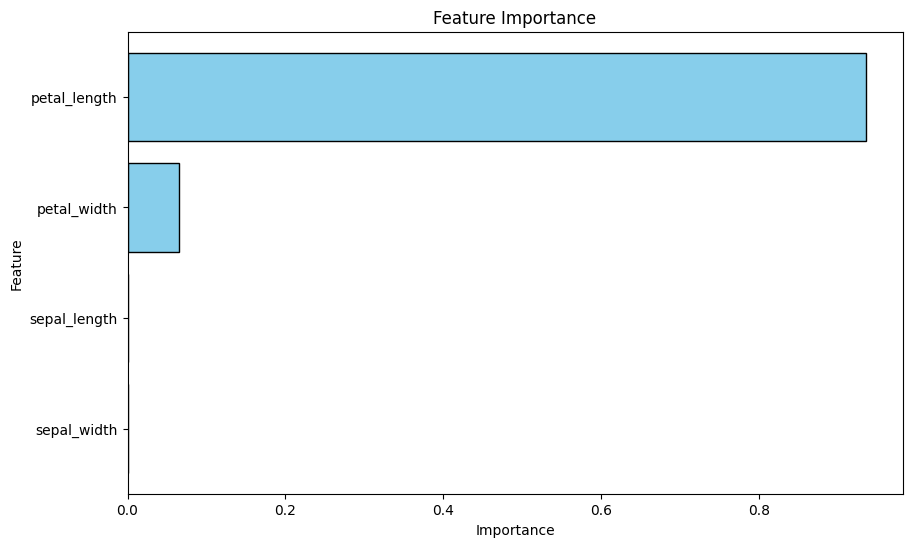

In [56]:
# Feature importance
importance_df = pd.DataFrame({"Feature": model.feature_names_in_, "Importance": model.feature_importances_})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="skyblue", edgecolor="black")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")
plt.gca().invert_yaxis()  # Invert y-axis to show the most important feature on top
plt.show()

### Decision Tree for Regression Datasets

### 🌳 Decision Tree კლასიფიკაცია (Classification)

- როდის გამოიყენება? – როცა მიზანია კატეგორიული ცვლადის პროგნოზირება.
- მიზანი: უნდა ვივარაუდოთ, თუ რომელ კლასს მიეკუთვნება ჩანაწერი (მაგ. „დიახ“ ან „არა“, „სპამი“ ან „არასპამი“).
- გაყოფის კრიტერიუმები: იყენებს მეტრიკებს, როგორიცაა:
  - Gini-ის არაწმინდე (Gini Impurity)
  - ენტროპია (Entropy / ინფორმაციული მოგება)  
- მაგალითი: ელფოსტა სპამია თუ არა - ტექსტის მიხედვით.

---

### 🌳 Decision Tree რეგრესია (Regression)

- როდის გამოიყენება? – როცა მიზანია რიცხვითი ცვლადის პროგნოზირება.
- მიზანი: უნდა ვივარაუდოთ ზუსტი რიცხვითი მნიშვნელობა (მაგ. ბინის ფასი, ტემპერატურა).
- გაყოფის კრიტერიუმები: იყენებს მეტრიკებს, როგორიცაა:
  - საშუალო კვადრატული შეცდომა (MSE)
  - საშუალო აბსოლუტური შეცდომა (MAE)
- მაგალითი: ბინის ფასის პროგნოზირება ზომის, ადგილმდებარეობისა და სხვა მახასიათებლების მიხედვით.

---


| მახასიათებელი           | კლასიფიკაცია                      | რეგრესია                            |
|------------------------|----------------------------------|------------------------------------|
| სამიზნე ცვლადი          | კატეგორიული (კლასები)             | რიცხვითი მნიშვნელობები (უწყვეტი)            |
| შედეგი                 | კლასის სახელწოდება               | რიცხვითი მნიშვნელობა               |
| გაყოფის კრიტერიუმი     | Gini, Entropy                    | MSE, MAE                          |
| შეფასების მეთოდები     | სიზუსტე, სრული დაფარვა   | RMSE, MAE, R²                     |

##  როგორ მუშაობს Decision Tree რეგრესია?

რეგრესიის დროს თითოეული ფოთოლი (leaf) შეიცავს იმ მონაცემების საშუალო მნიშვნელობას, რომლებიც ამ ფოთოლში ხვდებიან.

### მაგალითი:

ვთქვათ, გვინდა სახლის ფასის პროგნოზი.

- ფესვში გვაქვს ყველა მონაცემი:  
  `{100K, 120K, 130K, 150K, 160K, 300K}`

- ვყოფთ, ვთქვათ, `ფართობი > 100 კვ.მ` თუ არა:

  - მარცხნივ: `{100K, 120K, 130K}`
  - მარჯვნივ: `{150K, 160K, 300K}`

- ფოთლებში ამ მონაცემების საშუალო იქნება პროგნოზი:

  - მარცხენა ფოთოლი → `(100+120+130)/3 = 116.6K`
  - მარჯვენა ფოთოლი → `(150+160+300)/3 = 203.3K`

---

## შეფასების კრიტერიუმი – MSE

MSE ითვლის, **რამდენად შორს** არის პროგნოზები რეალური მნიშვნელობებისგან:

$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$

---

## უპირატესობები:

- მარტივად აღსაქმელია
- არ საჭიროებს მონაცემების ნორმალიზაციას
- მუშაობს როგორც ხაზოვან, ისე არალინეარულ დამოკიდებულებებზე

## შეზღუდვები:

- overfitting, თუ ზედმეტად ღრმა ხეა
- გრძნობიერია outlier-ების მიმართ 

In [57]:
X = np.array([[50], [60], [70], [80], [90], [100], [110], [120]])  # input: ფართობი
y = np.array([100, 110, 120, 130, 150, 170, 180, 200])   # output: ფასი ათასი €

In [58]:
# ვქმნით Decision Tree რეგრესორის ობიექტს და ვასწავლით
model = DecisionTreeRegressor(max_depth=2, random_state=0)
model.fit(X, y)

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [59]:
# პროგნოზი ფართობზე 95 კვ.მ
new_area = np.array([[95]])
predicted_price = model.predict(new_area)
print(f"ფართობი: 95 კვ.მ → პროგნოზირებული ფასი: {predicted_price[0]:.2f} ათასი €")

ფართობი: 95 კვ.მ → პროგნოზირებული ფასი: 160.00 ათასი €


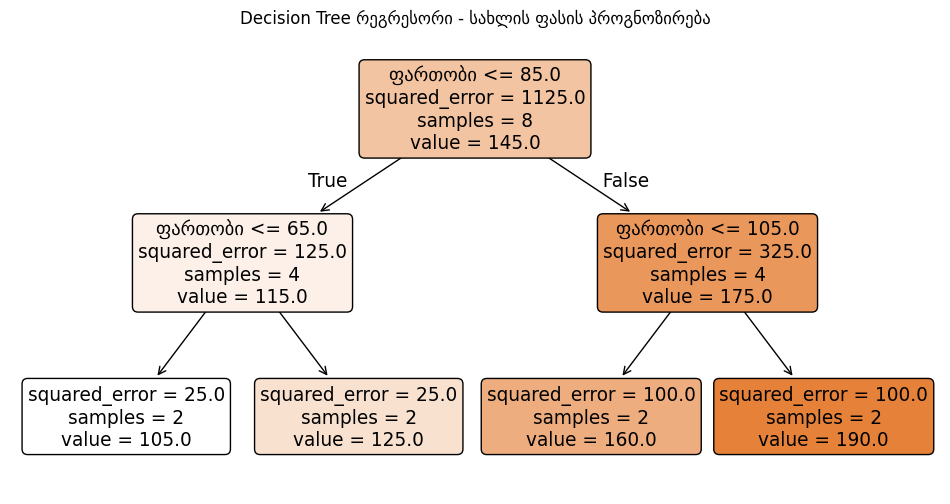

In [60]:
plt.figure(figsize=(12,6))
plot_tree(model, feature_names=["ფართობი"], filled=True, rounded=True)
plt.title("Decision Tree რეგრესორი - სახლის ფასის პროგნოზირება")
plt.show()